# MobileNetV2 — Ablation Study + Misclassified Images CSV
**Sunflower Alternaria Blight severity classification (6 classes)**

This notebook reuses your exact training pipeline (same `split.csv`, same transforms, same two-stage fine-tuning, AdamW, val macro-F1 selection) and adds:

1. **Ablation study (one-factor-at-a-time):** a baseline config (your current settings) vs. variants that change *one* hyperparameter/component at a time (LR, dropout, label smoothing, weight decay, batch size, balanced sampler, augmentation, frozen warm-up). Each run trains for a short fixed budget.
2. **Best-hyperparameter selection** using **validation macro-F1 only** (test set is never used for choosing).
3. **Final training** of the winning config (longer, with early stopping).
4. **Misclassified images → CSV** (`misclassified_test.csv`, plus the image files copied into folders).

**Before running:** put `split.csv` (the one you trained with) next to this notebook and set `DATA_ROOT` in Section 1. Do **not** regenerate the split.

Everything is saved to `ablation_outputs/`. The ablation loop saves after every run, so if Colab/your machine disconnects you can just re-run and it resumes.

## 0. Setup

In [15]:
import os, time, json, random, gc, shutil, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, cohen_kappa_score, roc_auc_score)
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Device: cuda


## 1. Configuration  (edit this cell)

In [2]:
# ---------- data ----------
DATA_ROOT = "/home/sem_7th/ATDL/Sunflower"   # same as your training notebook
SPLIT_CSV = "split.csv"                            # MUST be the same split.csv used for training
CLASS_NAMES = ["Class 1", "Class 2", "Class 3", "Class 4", "Class 5", "Class 6"]
SEVERITY_SCORE = {0: 0, 1: 1, 2: 3, 3: 5, 4: 7, 5: 9}
SEVERITY_LABEL = {0: "Immune", 1: "Resistant", 2: "MR", 3: "MS", 4: "S", 5: "HS"}

OUT_DIR = "ablation_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ---------- compute / budget ----------
PRETRAINED = True          # ImageNet weights (keep True; False only for debugging)
NUM_WORKERS = 4
SEEDS = [42]               # add more seeds e.g. [42, 7, 123] for more reliable results (runs take N x longer)

# short budget per ablation run
ABL_STAGE1_EPOCHS = 2      # frozen-backbone warm-up (baseline value)
ABL_STAGE2_EPOCHS = 10     # full fine-tune epochs
ABL_SCHED_PATIENCE = 3     # ReduceLROnPlateau patience for the short runs

# final training of the winning config
FINAL_STAGE1_EPOCHS = 10
FINAL_STAGE2_MAX = 200      # raise to 150 to match your original run
FINAL_PATIENCE = 25        # early-stopping patience on val macro-F1
FINAL_SCHED_PATIENCE = 8

MIN_GAIN = 0.005           # a change must beat baseline by >= 0.5 pt val macro-F1 to be adopted (noise guard)
COPY_MISCLASSIFIED_IMAGES = True

# ---------- baseline = your current MobileNetV2 notebook ----------
BASELINE = dict(
    lr_stage1=1e-3, lr_stage2=1e-5, weight_decay=1e-4, label_smoothing=0.05,
    dropout=0.3, batch_size=32, balanced_sampler=True, augmentation="full",
    stage1_epochs=ABL_STAGE1_EPOCHS,
)

# ---------- ablation grid: ONE factor changed at a time ----------
ABLATION_GRID = {
    "lr_stage2":        [1e-4, 5e-5, 1e-5, 5e-6],
    "lr_stage1":        [1e-3, 3e-4],
    "dropout":          [0.0, 0.2, 0.3, 0.5],
    "label_smoothing":  [0.0, 0.05, 0.1],
    "weight_decay":     [0.0, 1e-4, 1e-2],
    "batch_size":       [16, 32, 64],
    "balanced_sampler": [True, False],
    "augmentation":     ["none", "basic", "full"],
    "stage1_epochs":    [0, 2, 5],
}
assert all(k in BASELINE for k in ABLATION_GRID), "every grid factor must exist in BASELINE"

## 2. Load the split (same `split.csv` as training)

In [3]:
def is_valid_image_file(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

if not os.path.exists(SPLIT_CSV):
    print("WARNING: split.csv not found -> regenerating. Only do this if you never trained with a different split!")
    records = []
    for label_idx, cname in enumerate(CLASS_NAMES):
        class_dir = os.path.join(DATA_ROOT, cname)
        for fname in sorted(os.listdir(class_dir)):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                fpath = os.path.join(class_dir, fname)
                if is_valid_image_file(fpath):
                    records.append({"path": fpath, "label": label_idx})
    df_all = pd.DataFrame(records)
    train_df_, rest_df_ = train_test_split(df_all, test_size=0.30, stratify=df_all["label"], random_state=42)
    val_df_, test_df_ = train_test_split(rest_df_, test_size=0.50, stratify=rest_df_["label"], random_state=42)
    train_df_["split"], val_df_["split"], test_df_["split"] = "train", "val", "test"
    pd.concat([train_df_, val_df_, test_df_]).reset_index(drop=True).to_csv(SPLIT_CSV, index=False)

split_df = pd.read_csv(SPLIT_CSV)
missing = (~split_df["path"].apply(os.path.exists)).sum()
if missing:
    raise FileNotFoundError(f"{missing} image paths in {SPLIT_CSV} do not exist on this machine. "
                            f"Fix DATA_ROOT / paths in the CSV.")
split_df = split_df[split_df["path"].apply(is_valid_image_file)].reset_index(drop=True)
print(split_df.groupby(["split", "label"]).size().unstack(fill_value=0))

train_df = split_df[split_df.split == "train"].reset_index(drop=True)
val_df   = split_df[split_df.split == "val"].reset_index(drop=True)
test_df  = split_df[split_df.split == "test"].reset_index(drop=True)
print("train/val/test:", len(train_df), len(val_df), len(test_df))

label    0    1    2     3    4    5
split                               
test   140   89  160   218  157   67
train  650  415  751  1017  730  315
val    139   89  161   218  156   68
train/val/test: 3878 831 831


## 3. Data pipeline, model, training helpers

In [4]:
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
NORM = transforms.Normalize(MEAN, STD)

eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), NORM])

def get_train_tf(aug):
    if aug == "none":
        return eval_tf
    if aug == "basic":      # flips + small rotation only
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(0.5), transforms.RandomVerticalFlip(0.3),
            transforms.RandomRotation(15), transforms.ToTensor(), NORM])
    if aug == "full":       # identical to your training notebook
        return transforms.Compose([
            transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
            transforms.RandomHorizontalFlip(0.5), transforms.RandomVerticalFlip(0.3),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.15),
            transforms.ToTensor(), NORM,
            transforms.RandomErasing(p=0.15, scale=(0.02, 0.08))])
    raise ValueError(aug)

class LeafDataset(Dataset):
    def __init__(self, df, transform):
        self.paths, self.labels, self.transform = df["path"].tolist(), df["label"].tolist(), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            img = self.transform(img.convert("RGB"))
        return img, self.labels[idx]

loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
val_loader  = DataLoader(LeafDataset(val_df, eval_tf),  batch_size=64, shuffle=False, **loader_kwargs)
test_loader = DataLoader(LeafDataset(test_df, eval_tf), batch_size=64, shuffle=False, **loader_kwargs)

def make_train_loader(cfg, seed):
    bs = cfg["batch_size"]
    ds = LeafDataset(train_df, get_train_tf(cfg["augmentation"]))
    drop_last = (len(ds) % bs == 1)          # a final batch of 1 breaks BatchNorm in train mode
    if cfg["balanced_sampler"]:
        labels = train_df["label"].values
        counts = np.bincount(labels, minlength=len(CLASS_NAMES))
        w = torch.as_tensor((1.0 / np.maximum(counts, 1))[labels], dtype=torch.double)
        g = torch.Generator(); g.manual_seed(seed)
        sampler = WeightedRandomSampler(w, num_samples=len(w), replacement=True, generator=g)
        return DataLoader(ds, batch_size=bs, sampler=sampler, drop_last=drop_last, **loader_kwargs)
    return DataLoader(ds, batch_size=bs, shuffle=True, drop_last=drop_last, **loader_kwargs)

def build_model(dropout):
    w = models.MobileNet_V2_Weights.IMAGENET1K_V2 if PRETRAINED else None
    m = models.mobilenet_v2(weights=w)
    m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[1].in_features, len(CLASS_NAMES)))
    return m

def set_backbone_trainable(model, trainable):
    for name, p in model.named_parameters():
        if "classifier" not in name:
            p.requires_grad = trainable

def run_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train() if train_mode else model.eval()
    total_loss, preds, labs = 0.0, [], []
    with torch.set_grad_enabled(train_mode):
        for imgs, y in loader:
            imgs, y = imgs.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            out = model(imgs)
            loss = criterion(out, y)
            if train_mode:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            preds.append(out.argmax(1).cpu().numpy()); labs.append(y.cpu().numpy())
    preds, labs = np.concatenate(preds), np.concatenate(labs)
    f1 = precision_recall_fscore_support(labs, preds, average="macro", zero_division=0)[2]
    return total_loss / len(preds), accuracy_score(labs, preds), f1

def train_config(cfg, seed, stage1_epochs, stage2_epochs, patience, sched_patience, ckpt_path=None, verbose=False):
    """Two-stage training. Best checkpoint = highest VAL macro-F1 over all epochs. Returns (model_with_best_weights, summary, history_df)."""
    set_seed(seed)
    train_loader = make_train_loader(cfg, seed)
    model = build_model(cfg["dropout"]).to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    history = []
    st = dict(best_f1=-1.0, best_acc=0.0, best_epoch=-1, best_train_f1=float("nan"), best_weights=None, epoch=0)
    t0 = time.time()

    def one_epoch(optimizer, scheduler, stage):
        te = time.time()
        tr_loss, tr_acc, tr_f1 = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, va_f1 = run_epoch(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step(va_f1)
        history.append(dict(epoch=st["epoch"], stage=stage, train_loss=tr_loss, train_acc=tr_acc, train_f1=tr_f1,
                            val_loss=va_loss, val_acc=va_acc, val_f1=va_f1, epoch_time_s=time.time() - te))
        if verbose:
            print(f"[{st['epoch']:03d}|S{stage}] train_loss={tr_loss:.4f} train_f1={tr_f1:.4f} | "
                  f"val_loss={va_loss:.4f} val_acc={va_acc:.4f} val_f1={va_f1:.4f}")
        improved = va_f1 > st["best_f1"]
        if improved:
            st.update(best_f1=va_f1, best_acc=va_acc, best_epoch=st["epoch"], best_train_f1=tr_f1,
                      best_weights={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        st["epoch"] += 1
        return improved

    # Stage 1: frozen backbone, train head only
    if stage1_epochs > 0:
        set_backbone_trainable(model, False)
        opt1 = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                 lr=cfg["lr_stage1"], weight_decay=cfg["weight_decay"])
        for _ in range(stage1_epochs):
            one_epoch(opt1, None, 1)

    # Stage 2: full fine-tune with plateau LR decay + early stopping
    set_backbone_trainable(model, True)
    opt2 = torch.optim.AdamW(model.parameters(), lr=cfg["lr_stage2"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="max", factor=0.5, patience=sched_patience)
    no_improve = 0
    for _ in range(stage2_epochs):
        improved = one_epoch(opt2, sched, 2)
        no_improve = 0 if improved else no_improve + 1
        if no_improve >= patience:
            if verbose:
                print(f"Early stopping (no val_f1 gain for {patience} epochs).")
            break

    model.load_state_dict(st["best_weights"])
    if ckpt_path:
        torch.save(st["best_weights"], ckpt_path)
    summary = dict(best_val_f1=st["best_f1"], best_val_acc=st["best_acc"], best_epoch=st["best_epoch"],
                   epochs_run=st["epoch"], train_f1_at_best=st["best_train_f1"],
                   train_val_gap=st["best_train_f1"] - st["best_f1"], minutes=(time.time() - t0) / 60)
    return model, summary, pd.DataFrame(history)

## 4. Prediction + misclassified-images CSV helpers

In [5]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, labs = [], []
    for imgs, y in loader:
        probs.append(torch.softmax(model(imgs.to(DEVICE)), dim=1).cpu()); labs.append(y)
    return torch.cat(probs).numpy(), torch.cat(labs).numpy()

def dump_misclassified(model, split_name, tag, copy_images=COPY_MISCLASSIFIED_IMAGES):
    df = test_df if split_name == "test" else val_df
    loader = test_loader if split_name == "test" else val_loader
    probs, y_true = predict(model, loader)
    assert len(df) == len(y_true) and (df["label"].values == y_true).all(), "prediction order != dataframe order"
    y_pred = probs.argmax(1)

    out = pd.DataFrame({
        "split": split_name,
        "path": df["path"].values,
        "filename": df["path"].map(os.path.basename).values,
        "true_label": y_true,
        "true_class": [CLASS_NAMES[i] for i in y_true],
        "true_severity": [SEVERITY_LABEL[i] for i in y_true],
        "pred_label": y_pred,
        "pred_class": [CLASS_NAMES[i] for i in y_pred],
        "pred_severity": [SEVERITY_LABEL[i] for i in y_pred],
        "severity_score_error": [abs(SEVERITY_SCORE[a] - SEVERITY_SCORE[b]) for a, b in zip(y_true, y_pred)],
        "confidence": probs.max(1),
        "correct": y_true == y_pred,
    })
    for i, c in enumerate(CLASS_NAMES):
        out[f"prob_{c}"] = probs[:, i]
    out.to_csv(f"{OUT_DIR}/predictions_{split_name}_{tag}.csv", index=False)

    mis = out[~out["correct"]].sort_values("confidence", ascending=False).reset_index(drop=True)  # most confident mistakes first
    if copy_images:
        copied = []
        for i, r in mis.iterrows():
            folder = os.path.join(OUT_DIR, f"misclassified_images_{tag}", split_name,
                                  f"true_{r.true_class}__pred_{r.pred_class}".replace(" ", ""))
            os.makedirs(folder, exist_ok=True)
            dest = os.path.join(folder, f"{i:03d}_{r.filename}")
            shutil.copy2(r.path, dest)
            copied.append(dest)
        mis["copied_path"] = copied
    mis.to_csv(f"{OUT_DIR}/misclassified_{split_name}_{tag}.csv", index=False)

    n_wrong = len(mis)
    adj = int((mis["true_label"] - mis["pred_label"]).abs().eq(1).sum())
    print(f"[{split_name}/{tag}] accuracy={1 - n_wrong / len(out):.4f} | misclassified {n_wrong}/{len(out)} "
          f"| {adj} of them are adjacent-class (off by one severity level)")
    print(f"   saved -> {OUT_DIR}/misclassified_{split_name}_{tag}.csv")
    return out, mis

### (Optional shortcut) Misclassified CSV from your **existing** trained checkpoint
Your `best_MobileNetV2.pth (1).zip` is just the PyTorch checkpoint (`.pth` files are zip-format internally) — **rename it to `best_MobileNetV2.pth`, don't unzip it**. Set the path below to get a misclassified-images CSV for your current model right away (dropout 0.3, same as training). Skip this cell if you only want the ablation results.

In [6]:
EXISTING_CKPT = None   # e.g. "best_MobileNetV2.pth"
if EXISTING_CKPT:
    orig_model = build_model(0.3).to(DEVICE)
    orig_model.load_state_dict(torch.load(EXISTING_CKPT, map_location=DEVICE))
    _ = dump_misclassified(orig_model, "test", "original_model")
    del orig_model

## 5. Run the ablation study
Each run = baseline with **one** thing changed, trained for `ABL_STAGE1_EPOCHS + ABL_STAGE2_EPOCHS` epochs, scored by **best validation macro-F1**. Results are appended to `ablation_outputs/ablation_results.csv` after every run (safe to interrupt and re-run).

Rough cost: 19 runs × ~12 epochs. At your earlier ~65 s/epoch that's about 4 hours on one seed — trim `ABLATION_GRID` in Section 1 if you're short on time.

In [7]:
def build_runs():
    runs, meta = {"baseline": dict(BASELINE)}, {"baseline": ("baseline", "-")}
    for factor, values in ABLATION_GRID.items():
        for v in values:
            if v == BASELINE[factor]:
                continue
            cfg = dict(BASELINE); cfg[factor] = v
            name = f"{factor}={v}"
            runs[name], meta[name] = cfg, (factor, v)
    return runs, meta

runs, meta = build_runs()
print(f"{len(runs)} configs x {len(SEEDS)} seed(s) = {len(runs) * len(SEEDS)} runs")
for n in runs:
    print("  ", n)

19 configs x 1 seed(s) = 19 runs
   baseline
   lr_stage2=0.0001
   lr_stage2=5e-05
   lr_stage2=5e-06
   lr_stage1=0.0003
   dropout=0.0
   dropout=0.2
   dropout=0.5
   label_smoothing=0.0
   label_smoothing=0.1
   weight_decay=0.0
   weight_decay=0.01
   batch_size=16
   batch_size=64
   balanced_sampler=False
   augmentation=none
   augmentation=basic
   stage1_epochs=0
   stage1_epochs=5


In [8]:
RESULTS_CSV = f"{OUT_DIR}/ablation_results.csv"

def log_result(name, factor, value, seed, cfg, summary):
    row = {"run": name, "factor": factor, "value": str(value), "seed": seed, **cfg, **summary}
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)

def already_done():
    if not os.path.exists(RESULTS_CSV):
        return set()
    r = pd.read_csv(RESULTS_CSV)
    return set(zip(r["run"], r["seed"]))

done = already_done()
for name, cfg in runs.items():
    for seed in SEEDS:
        if (name, seed) in done:
            print(f"skip (done): {name} seed={seed}")
            continue
        print(f"\n>>> {name} | seed {seed}")
        model, summ, _ = train_config(cfg, seed, cfg["stage1_epochs"], ABL_STAGE2_EPOCHS,
                                      patience=ABL_STAGE2_EPOCHS, sched_patience=ABL_SCHED_PATIENCE)
        log_result(name, meta[name][0], meta[name][1], seed, cfg, summ)
        print(f"    val_macro_F1={summ['best_val_f1']:.4f}  val_acc={summ['best_val_acc']:.4f}  "
              f"best_epoch={summ['best_epoch']}  gap={summ['train_val_gap']:+.3f}  ({summ['minutes']:.1f} min)")
        del model; gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
print("\nAblation runs complete.")

skip (done): baseline seed=42
skip (done): lr_stage2=0.0001 seed=42
skip (done): lr_stage2=5e-05 seed=42
skip (done): lr_stage2=5e-06 seed=42
skip (done): lr_stage1=0.0003 seed=42
skip (done): dropout=0.0 seed=42
skip (done): dropout=0.2 seed=42
skip (done): dropout=0.5 seed=42
skip (done): label_smoothing=0.0 seed=42
skip (done): label_smoothing=0.1 seed=42
skip (done): weight_decay=0.0 seed=42
skip (done): weight_decay=0.01 seed=42
skip (done): batch_size=16 seed=42
skip (done): batch_size=64 seed=42
skip (done): balanced_sampler=False seed=42
skip (done): augmentation=none seed=42
skip (done): augmentation=basic seed=42
skip (done): stage1_epochs=0 seed=42
skip (done): stage1_epochs=5 seed=42

Ablation runs complete.


## 6. Ablation summary (validation macro-F1)

,run,factor,value,val_f1,val_f1_std,val_acc,best_epoch,train_val_gap,n_seeds,delta_vs_baseline
0,lr_stage2=0.0001,lr_stage2,0.0001,0.8203,NaN,0.8002,10.0,0.0417,1,0.0797
1,combined_best,combined,lr_stage2=0.0001 + batch_size=16 + balanced_sa...,0.8193,NaN,0.8075,9.0,0.1569,1,0.0787
2,lr_stage2=5e-05,lr_stage2,5e-05,0.8039,NaN,0.7858,10.0,0.0255,1,0.0633
3,augmentation=none,augmentation,none,0.7720,NaN,0.7509,10.0,0.0727,1,0.0314
4,balanced_sampler=False,balanced_sampler,False,0.7607,NaN,0.7413,11.0,0.0017,1,0.0201
5,augmentation=basic,augmentation,basic,0.7509,NaN,0.7280,10.0,0.0315,1,0.0103
6,batch_size=16,batch_size,16,0.7461,NaN,0.7256,8.0,-0.0007,1,0.0055
7,stage1_epochs=5,stage1_epochs,5,0.7427,NaN,0.7184,14.0,0.0288,1,0.0021
8,weight_decay=0.0,weight_decay,0.0,0.7426,NaN,0.7148,11.0,0.0154,1,0.0020
9,dropout=0.2,dropout,0.2,0.7417,NaN,0.7160,9.0,0.0231,1,0.0011


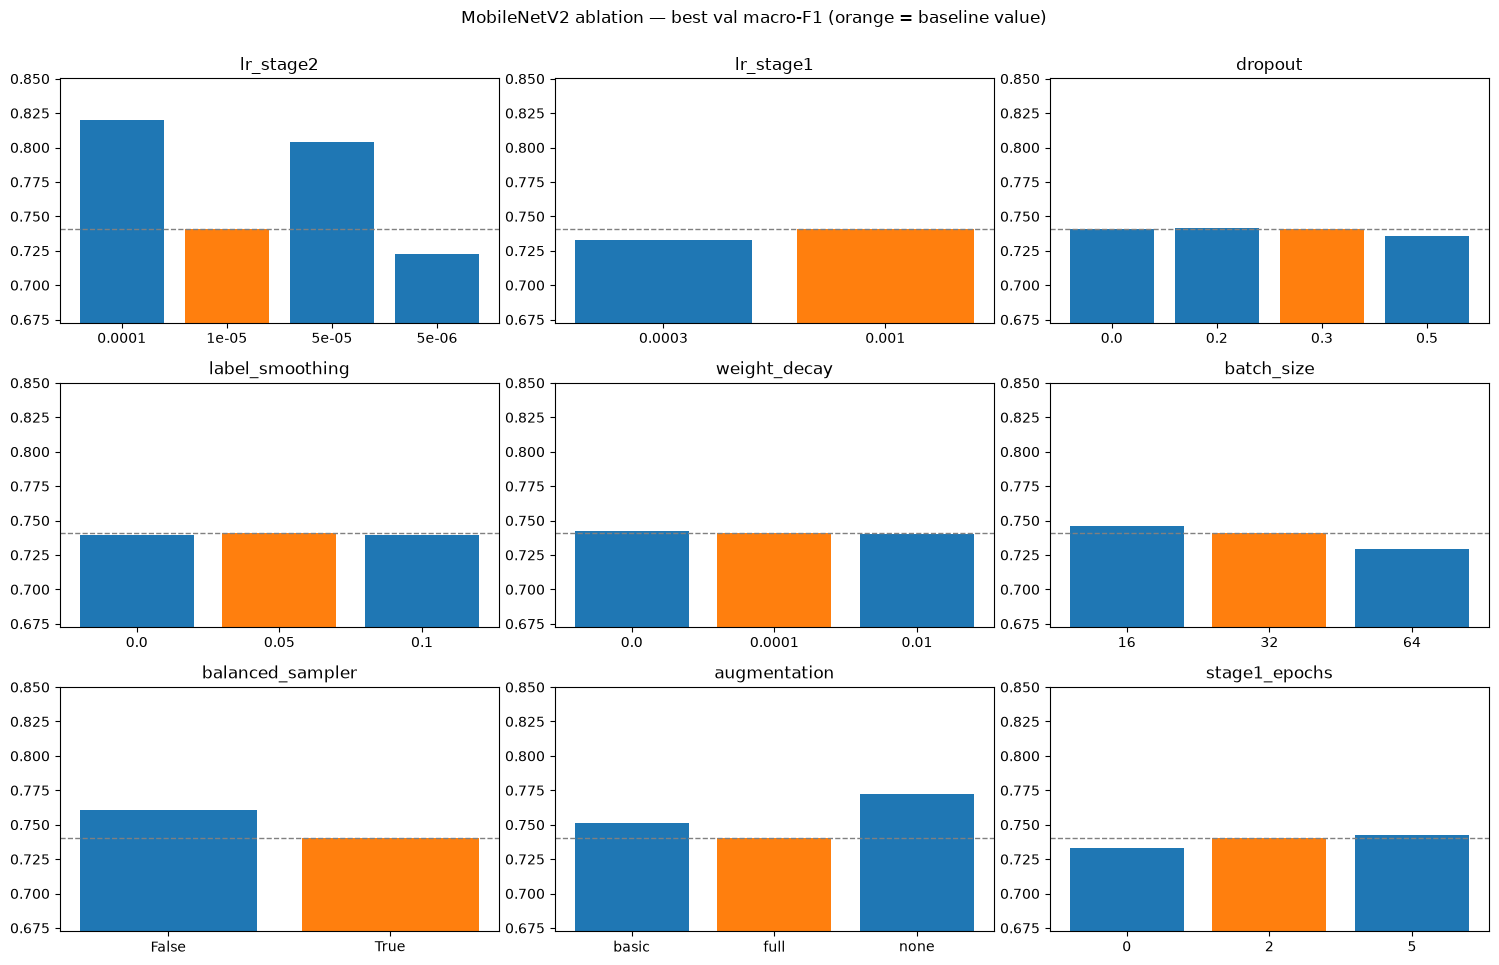

In [9]:
def make_summary():
    r = pd.read_csv(RESULTS_CSV)
    s = (r.groupby(["run", "factor", "value"], as_index=False)
           .agg(val_f1=("best_val_f1", "mean"), val_f1_std=("best_val_f1", "std"),
                val_acc=("best_val_acc", "mean"), best_epoch=("best_epoch", "mean"),
                train_val_gap=("train_val_gap", "mean"), n_seeds=("seed", "count")))
    base = s.loc[s.run == "baseline", "val_f1"].iloc[0]
    s["delta_vs_baseline"] = s["val_f1"] - base
    return s.sort_values("val_f1", ascending=False).reset_index(drop=True)

summary = make_summary()
summary.to_csv(f"{OUT_DIR}/ablation_summary.csv", index=False)
display(summary.round(4))

# one panel per factor
plot_df = summary[~summary.factor.isin(["combined"])].copy()
factors = [f for f in ABLATION_GRID if f in set(plot_df.factor)]
fig, axes = plt.subplots(int(np.ceil(len(factors) / 3)), 3, figsize=(15, 3.2 * int(np.ceil(len(factors) / 3))))
axes = np.atleast_1d(axes).ravel()
base_row = summary[summary.run == "baseline"].iloc[0]
for ax, f in zip(axes, factors):
    sub = plot_df[plot_df.factor == f].copy()
    sub = pd.concat([sub, base_row.to_frame().T.assign(value=str(BASELINE[f]))]).drop_duplicates("value")
    sub = sub.sort_values("value")
    colors = ["tab:orange" if str(v) == str(BASELINE[f]) else "tab:blue" for v in sub["value"]]
    ax.bar(sub["value"].astype(str), sub["val_f1"].astype(float), color=colors)
    ax.axhline(float(base_row.val_f1), color="gray", ls="--", lw=1)
    ax.set_title(f); ax.set_ylim(max(0, float(plot_df.val_f1.min()) - 0.05), float(plot_df.val_f1.max()) + 0.03)
for ax in axes[len(factors):]:
    ax.axis("off")
plt.suptitle("MobileNetV2 ablation — best val macro-F1 (orange = baseline value)", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ablation_plot.png", dpi=150); plt.show()

## 7. Pick the best hyperparameters
For each factor, take the best value **only if it beats the baseline by at least `MIN_GAIN`** (otherwise differences are within noise on a ~700-image validation set). The adopted changes are combined into one config, which is then trained with the same short budget and compared against the baseline and the best single change. The winner (by val macro-F1) is used for final training.

In [10]:
best_cfg, chosen = dict(BASELINE), []
for factor in ABLATION_GRID:
    sub = summary[summary.factor == factor]
    if sub.empty:
        continue
    top = sub.iloc[0]                               # summary is sorted by val_f1 desc
    if top.delta_vs_baseline >= MIN_GAIN:
        best_cfg[factor] = runs[top.run][factor]    # keep the original python type
        chosen.append(f"{factor}={best_cfg[factor]}")
print("Adopted single-factor changes:", chosen if chosen else "none (baseline already best within noise)")

if chosen:
    name = "combined_best"
    for seed in SEEDS:
        if (name, seed) in already_done():
            continue
        print(f"\n>>> {name} | seed {seed}")
        model, summ, _ = train_config(best_cfg, seed, best_cfg["stage1_epochs"], ABL_STAGE2_EPOCHS,
                                      patience=ABL_STAGE2_EPOCHS, sched_patience=ABL_SCHED_PATIENCE)
        log_result(name, "combined", " + ".join(chosen), seed, best_cfg, summ)
        print(f"    val_macro_F1={summ['best_val_f1']:.4f}")
        del model; gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    runs[name] = best_cfg

summary = make_summary()
summary.to_csv(f"{OUT_DIR}/ablation_summary.csv", index=False)

# candidates: baseline, combined (if any), best single-factor run
cands = {"baseline": dict(BASELINE)}
if chosen:
    cands["combined_best"] = best_cfg
singles = summary[~summary.run.isin(["baseline", "combined_best"])]
if len(singles):
    cands[singles.iloc[0].run] = runs[singles.iloc[0].run]
score = {n: float(summary.loc[summary.run == n, "val_f1"].iloc[0]) for n in cands}
print("\nCandidate val macro-F1:", {k: round(v, 4) for k, v in score.items()})

FINAL_NAME = max(score, key=score.get)
FINAL_CFG = cands[FINAL_NAME]
print("\n=== SELECTED:", FINAL_NAME, "===")
print(json.dumps(FINAL_CFG, indent=2))
with open(f"{OUT_DIR}/best_config.json", "w") as f:
    json.dump({"selected_run": FINAL_NAME, "config": FINAL_CFG, "val_macro_f1_short_budget": score[FINAL_NAME],
               "all_candidate_scores": score}, f, indent=2)

Adopted single-factor changes: ['lr_stage2=0.0001', 'batch_size=16', 'balanced_sampler=False', 'augmentation=none']

Candidate val macro-F1: {'baseline': 0.7406, 'combined_best': 0.8193, 'lr_stage2=0.0001': 0.8203}

=== SELECTED: lr_stage2=0.0001 ===
{
  "lr_stage1": 0.001,
  "lr_stage2": 0.0001,
  "weight_decay": 0.0001,
  "label_smoothing": 0.05,
  "dropout": 0.3,
  "batch_size": 32,
  "balanced_sampler": true,
  "augmentation": "full",
  "stage1_epochs": 2
}


## 8. Final training with the selected config
Full run with early stopping on val macro-F1 (budget set in Section 1). Warm-up length: `FINAL_STAGE1_EPOCHS` if the selected config uses a warm-up, `0` if the ablation chose no warm-up.

[000|S1] train_loss=1.2522 train_f1=0.5812 | val_loss=1.0681 val_acc=0.6233 val_f1=0.6476
[001|S1] train_loss=0.9807 train_f1=0.6583 | val_loss=0.9542 val_acc=0.6582 val_f1=0.6730
[002|S1] train_loss=0.9165 train_f1=0.6907 | val_loss=0.9291 val_acc=0.6667 val_f1=0.6801
[003|S1] train_loss=0.8996 train_f1=0.6916 | val_loss=0.9336 val_acc=0.6462 val_f1=0.6707
[004|S1] train_loss=0.8784 train_f1=0.6950 | val_loss=0.9010 val_acc=0.6703 val_f1=0.6870
[005|S1] train_loss=0.8802 train_f1=0.6961 | val_loss=0.9133 val_acc=0.6751 val_f1=0.6833
[006|S1] train_loss=0.8694 train_f1=0.7000 | val_loss=0.9099 val_acc=0.6631 val_f1=0.6751
[007|S1] train_loss=0.8701 train_f1=0.7034 | val_loss=0.8937 val_acc=0.6679 val_f1=0.6900
[008|S1] train_loss=0.8578 train_f1=0.7107 | val_loss=0.9046 val_acc=0.6498 val_f1=0.6756
[009|S1] train_loss=0.8409 train_f1=0.7222 | val_loss=0.8775 val_acc=0.6811 val_f1=0.6979
[010|S2] train_loss=0.7976 train_f1=0.7471 | val_loss=0.7916 val_acc=0.7316 val_f1=0.7536
[011|S2] t

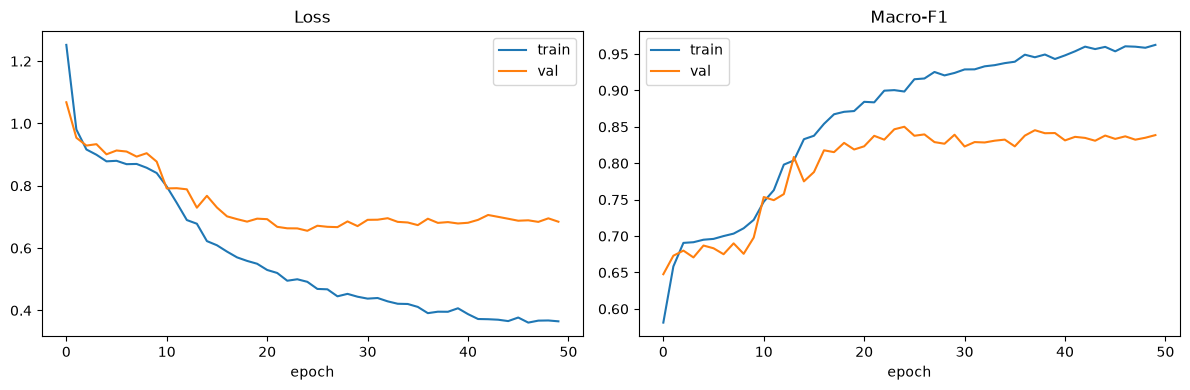

In [11]:
final_stage1 = 0 if FINAL_CFG["stage1_epochs"] == 0 else max(FINAL_STAGE1_EPOCHS, FINAL_CFG["stage1_epochs"])
final_model, final_summ, final_hist = train_config(
    FINAL_CFG, SEEDS[0], final_stage1, FINAL_STAGE2_MAX,
    patience=FINAL_PATIENCE, sched_patience=FINAL_SCHED_PATIENCE,
    ckpt_path=f"{OUT_DIR}/best_MobileNetV2_ablation.pth", verbose=True)
final_hist.to_csv(f"{OUT_DIR}/history_MobileNetV2_ablation.csv", index=False)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in final_summ.items()})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(final_hist.epoch, final_hist.train_loss, label="train"); ax[0].plot(final_hist.epoch, final_hist.val_loss, label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(final_hist.epoch, final_hist.train_f1, label="train"); ax[1].plot(final_hist.epoch, final_hist.val_f1, label="val")
ax[1].set_title("Macro-F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves_ablation.png", dpi=150); plt.show()

In [12]:

def compute_model_profile(model, img_size=IMG_SIZE, repeats=50, warmup=10):
    """Compute parameter count, serialized model size, THOP compute, and CPU/GPU latency."""
    was_training = model.training
    original_device = next(model.parameters()).device

    params_total = sum(p.numel() for p in model.parameters())
    params_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # Serialized state_dict size in MB
    import io
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    model_size_mb = buffer.getbuffer().nbytes / (1024 ** 2)

    # THOP profile (THOP reports MACs; retain the conventional notebook label GFLOPs)
    model.eval()
    profile_device = original_device
    dummy = torch.randn(1, 3, img_size, img_size, device=profile_device)
    with torch.no_grad():
        macs, _ = thop_profile(model, inputs=(dummy,), verbose=False)
    gflops = macs / 1e9
    del dummy

    def measure_latency(device):
        m = model.to(device).eval()
        x = torch.randn(1, 3, img_size, img_size, device=device)
        with torch.no_grad():
            for _ in range(warmup):
                _ = m(x)
            if device.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            for _ in range(repeats):
                _ = m(x)
            if device.type == "cuda":
                torch.cuda.synchronize()
            elapsed_ms = (time.perf_counter() - t0) * 1000.0 / repeats
        del x
        return elapsed_ms

    inference_latency_gpu_ms = None
    if torch.cuda.is_available():
        inference_latency_gpu_ms = measure_latency(torch.device("cuda"))

    inference_latency_cpu_ms = measure_latency(torch.device("cpu"))

    # Restore original device/training state
    model.to(original_device)
    model.train(was_training)

    return {
        "params_total": params_total,
        "params_trainable": params_trainable,
        "model_size_mb": model_size_mb,
        "gflops": gflops,
        "inference_latency_gpu_ms": inference_latency_gpu_ms,
        "inference_latency_cpu_ms": inference_latency_cpu_ms,
    }


def compute_test_metrics(test_all, final_hist, final_model):
    y_true = test_all["true_label"].values
    y_pred = test_all["pred_label"].values

    # Macro and weighted classification metrics
    acc = accuracy_score(y_true, y_pred)
    pm, rm, fm, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    pw, rw, fw, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    kappa = cohen_kappa_score(y_true, y_pred, weights="quadratic")

    # Specificity per class = TN / (TN + FP), then macro average
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
    specificity = []
    for i in range(len(CLASS_NAMES)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp
        specificity.append(tn / (tn + fp) if (tn + fp) else 0.0)
    specificity_macro = float(np.mean(specificity))

    # One-vs-rest macro ROC-AUC from the stored class probabilities
    prob_cols = [f"prob_{c}" for c in CLASS_NAMES]
    y_prob = test_all[prob_cols].values
    y_true_onehot = np.eye(len(CLASS_NAMES))[y_true]
    auc_roc_ovr_macro = roc_auc_score(
        y_true_onehot, y_prob, multi_class="ovr", average="macro"
    )

    # Average measured training time per epoch
    avg_train_time_per_epoch_s = float(final_hist["epoch_time_s"].mean())

    profile = compute_model_profile(final_model)

    return {
        "accuracy": acc,
        "precision_macro": pm,
        "recall_macro": rm,
        "f1_macro": fm,
        "precision_weighted": pw,
        "recall_weighted": rw,
        "f1_weighted": fw,
        "specificity_macro": specificity_macro,
        "auc_roc_ovr_macro": auc_roc_ovr_macro,
        "cohen_kappa_quadratic": kappa,
        "params_total": profile["params_total"],
        "params_trainable": profile["params_trainable"],
        "model_size_mb": profile["model_size_mb"],
        "gflops": profile["gflops"],
        "avg_train_time_per_epoch_s": avg_train_time_per_epoch_s,
        "epochs_run": int(final_summ["epochs_run"]),
        "inference_latency_gpu_ms": profile["inference_latency_gpu_ms"],
        "inference_latency_cpu_ms": profile["inference_latency_cpu_ms"],
        "img_size": IMG_SIZE,
        "batch_size": FINAL_CFG["batch_size"],
        "seed": SEEDS[0],
    }


## 9. Test-set evaluation + misclassified images CSV

THOP profile imported successfully.
[test/ablation_best] accuracy=0.8111 | misclassified 157/831 | 156 of them are adjacent-class (off by one severity level)
   saved -> ablation_outputs/misclassified_test_ablation_best.csv
[val/ablation_best] accuracy=0.8327 | misclassified 139/831 | 135 of them are adjacent-class (off by one severity level)
   saved -> ablation_outputs/misclassified_val_ablation_best.csv

MOBILENETV2 — FINAL TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00       140
     Class 2       0.82      0.88      0.85        89
     Class 3       0.73      0.69      0.71       160
     Class 4       0.72      0.75      0.74       218
     Class 5       0.80      0.76      0.78       157
     Class 6       0.92      0.91      0.92        67

    accuracy                           0.81       831
   macro avg       0.83      0.83      0.83       831
weighted avg       0.81      0.81      0.81       831


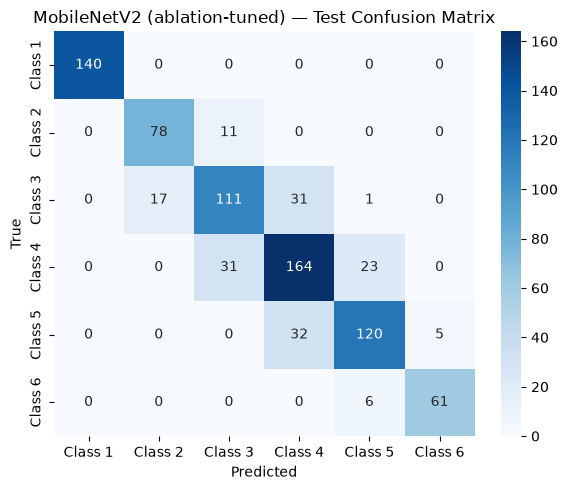


Final test results saved to: ablation_outputs/final_test_results.csv

Misclassified test samples:


,filename,true_class,pred_class,confidence,severity_score_error
0,IMG_20251128_134442338_HDR.jpg,Class 6,Class 5,0.976227,2
1,IMG_20251128_135408.jpg,Class 3,Class 2,0.968796,2
2,IMG-20251128-WA0847.jpg,Class 3,Class 4,0.965060,2
3,IMG20251128133458.jpg,Class 5,Class 4,0.959406,2
4,20251128_133723.jpg,Class 2,Class 3,0.955533,2
5,IMG_20251128_132850.jpg,Class 3,Class 2,0.952959,2
6,IMG_20251128_135446471_HDR.jpg,Class 6,Class 5,0.952138,2
7,IMG_20251128_133804.jpg,Class 5,Class 6,0.936593,2
8,20251128_131923.jpg,Class 2,Class 3,0.935190,2
9,IMG_20251128_132540.jpg,Class 5,Class 4,0.927873,2



Calculating reference-style metrics...
This includes model profiling and inference latency.

REFERENCE-STYLE FINAL MODEL METRICS
model                         MobileNetV2
accuracy                         0.811071
precision_macro                  0.832209
recall_macro                     0.832871
f1_macro                         0.832204
precision_weighted               0.811281
recall_weighted                  0.811071
f1_weighted                      0.810851
specificity_macro                0.960111
auc_roc_ovr_macro                0.968334
cohen_kappa_quadratic            0.958628
params_total                      2231558
params_trainable                  2231558
model_size_mb                    8.745555
gflops                           0.326214
avg_train_time_per_epoch_s      92.859359
epochs_run                             50
inference_latency_gpu_ms         1.203572
inference_latency_cpu_ms         7.495038
img_size                              224
batch_size                    

In [18]:
# ============================================================
# FINAL EVALUATION: MobileNetV2 (Ablation-Tuned)
# Fix: NameError: name 'thop_profile' is not defined
# No kernel restart or model retraining required
# ============================================================

# ---------- 1. Import the missing THOP function ----------
from thop import profile as thop_profile

import time
import io
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    cohen_kappa_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

print("THOP profile imported successfully.")


# ============================================================
# 2. Model profiling function
# ============================================================

def compute_model_profile(model, img_size=IMG_SIZE, repeats=50, warmup=10):
    """
    Calculate:
    - Total parameters
    - Trainable parameters
    - Model size in MB
    - Computational cost using THOP
    - CPU inference latency
    - GPU inference latency, if CUDA is available
    """

    was_training = model.training
    original_device = next(model.parameters()).device

    # ---------- Parameter counts ----------
    params_total = sum(
        p.numel() for p in model.parameters()
    )

    params_trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    # ---------- Serialized model size ----------
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)

    model_size_mb = (
        buffer.getbuffer().nbytes / (1024 ** 2)
    )

    # ---------- THOP computational profiling ----------
    model.eval()

    dummy = torch.randn(
        1, 3, img_size, img_size,
        device=original_device
    )

    try:
        with torch.no_grad():
            macs, _ = thop_profile(
                model,
                inputs=(dummy,),
                verbose=False
            )

        # THOP reports MACs. Preserve the original
        # notebook's convention of reporting MACs / 1e9.
        gflops = macs / 1e9

    finally:
        del dummy

    # ---------- Inference latency ----------
    def measure_latency(device):

        m = model.to(device).eval()

        x = torch.randn(
            1, 3, img_size, img_size,
            device=device
        )

        try:
            with torch.no_grad():

                # Warm-up iterations
                for _ in range(warmup):
                    _ = m(x)

                if device.type == "cuda":
                    torch.cuda.synchronize()

                # Timed iterations
                start_time = time.perf_counter()

                for _ in range(repeats):
                    _ = m(x)

                if device.type == "cuda":
                    torch.cuda.synchronize()

                elapsed_ms = (
                    (time.perf_counter() - start_time)
                    * 1000.0 / repeats
                )

        finally:
            del x

        return elapsed_ms

    inference_latency_gpu_ms = None
    inference_latency_cpu_ms = None

    try:
        # GPU latency, when available
        if torch.cuda.is_available():
            inference_latency_gpu_ms = measure_latency(
                torch.device("cuda")
            )

        # CPU latency
        inference_latency_cpu_ms = measure_latency(
            torch.device("cpu")
        )

    finally:
        # Restore original device and training/evaluation state
        model.to(original_device)
        model.train(was_training)

    return {
        "params_total": params_total,
        "params_trainable": params_trainable,
        "model_size_mb": model_size_mb,
        "gflops": gflops,
        "inference_latency_gpu_ms": inference_latency_gpu_ms,
        "inference_latency_cpu_ms": inference_latency_cpu_ms,
    }


# ============================================================
# 3. Complete test metrics function
# ============================================================

def compute_test_metrics(test_all, final_hist, final_model):

    # ---------- Actual and predicted labels ----------
    y_true = test_all["true_label"].values
    y_pred = test_all["pred_label"].values

    # ---------- Classification metrics ----------
    acc = accuracy_score(y_true, y_pred)

    pm, rm, fm, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    pw, rw, fw, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    # ---------- Confusion matrix ----------
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(CLASS_NAMES))
    )

    # ---------- Macro specificity ----------
    specificity = []

    for i in range(len(CLASS_NAMES)):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = cm.sum() - tp - fn - fp

        if (tn + fp) > 0:
            specificity.append(
                tn / (tn + fp)
            )
        else:
            specificity.append(0.0)

    specificity_macro = float(
        np.mean(specificity)
    )

    # ---------- ROC-AUC ----------
    prob_cols = [
        f"prob_{c}" for c in CLASS_NAMES
    ]

    y_prob = test_all[prob_cols].values

    y_true_onehot = np.eye(
        len(CLASS_NAMES)
    )[y_true]

    auc_roc_ovr_macro = roc_auc_score(
        y_true_onehot,
        y_prob,
        multi_class="ovr",
        average="macro"
    )

    # ---------- Average training time ----------
    avg_train_time_per_epoch_s = float(
        final_hist["epoch_time_s"].mean()
    )

    # ---------- Model profiling ----------
    profile = compute_model_profile(
        final_model
    )

    # ---------- Return all metrics ----------
    return {
        "accuracy": acc,

        "precision_macro": pm,
        "recall_macro": rm,
        "f1_macro": fm,

        "precision_weighted": pw,
        "recall_weighted": rw,
        "f1_weighted": fw,

        "specificity_macro": specificity_macro,
        "auc_roc_ovr_macro": auc_roc_ovr_macro,
        "cohen_kappa_quadratic": kappa,

        "params_total": profile["params_total"],
        "params_trainable": profile["params_trainable"],
        "model_size_mb": profile["model_size_mb"],
        "gflops": profile["gflops"],

        "avg_train_time_per_epoch_s": (
            avg_train_time_per_epoch_s
        ),

        "epochs_run": int(
            final_summ["epochs_run"]
        ),

        "inference_latency_gpu_ms": (
            profile["inference_latency_gpu_ms"]
        ),

        "inference_latency_cpu_ms": (
            profile["inference_latency_cpu_ms"]
        ),

        "img_size": IMG_SIZE,
        "batch_size": FINAL_CFG["batch_size"],
        "seed": SEEDS[0],
    }


# ============================================================
# 4. Generate test and validation predictions
# ============================================================

test_all, test_mis = dump_misclassified(
    final_model,
    "test",
    "ablation_best"
)

val_all, val_mis = dump_misclassified(
    final_model,
    "val",
    "ablation_best"
)


# ============================================================
# 5. Calculate classification metrics
# ============================================================

y_true = test_all["true_label"].values
y_pred = test_all["pred_label"].values

acc = accuracy_score(
    y_true,
    y_pred
)

pm, rm, fm, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

fw = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)[2]

kappa = cohen_kappa_score(
    y_true,
    y_pred,
    weights="quadratic"
)


# ============================================================
# 6. Print classification report
# ============================================================

print("\n" + "=" * 65)
print("MOBILENETV2 — FINAL TEST CLASSIFICATION REPORT")
print("=" * 65)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print(
    f"TEST Accuracy = {acc:.4f} | "
    f"Macro Precision/Recall/F1 = "
    f"{pm:.4f}/{rm:.4f}/{fm:.4f} | "
    f"Weighted F1 = {fw:.4f} | "
    f"QWK = {kappa:.4f}"
)


# ============================================================
# 7. Plot and save confusion matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("True")

plt.title(
    "MobileNetV2 (ablation-tuned) — Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    f"{OUT_DIR}/confusion_matrix_ablation.png",
    dpi=150
)

plt.show()


# ============================================================
# 8. Save final test results
# ============================================================

final_results = pd.DataFrame([
    {
        "selected_run": FINAL_NAME,
        **FINAL_CFG,

        "test_accuracy": acc,
        "test_precision_macro": pm,
        "test_recall_macro": rm,
        "test_f1_macro": fm,
        "test_f1_weighted": fw,
        "test_qwk": kappa,

        "n_test": len(test_all),
        "n_misclassified": len(test_mis),

        "epochs_run": final_summ["epochs_run"],
    }
])

final_results.to_csv(
    f"{OUT_DIR}/final_test_results.csv",
    index=False
)

print(
    f"\nFinal test results saved to: "
    f"{OUT_DIR}/final_test_results.csv"
)


# ============================================================
# 9. Display misclassified test images
# ============================================================

print("\nMisclassified test samples:")

display(
    test_mis[
        [
            "filename",
            "true_class",
            "pred_class",
            "confidence",
            "severity_score_error"
        ]
    ].head(15)
)


# ============================================================
# 10. Calculate expanded reference-style metrics
# ============================================================

print("\nCalculating reference-style metrics...")
print("This includes model profiling and inference latency.")

metrics = compute_test_metrics(
    test_all,
    final_hist,
    final_model
)

reference_output = {
    "model": "MobileNetV2",
    **metrics,
}


# ============================================================
# 11. Print reference-style metrics
# ============================================================

print("\n" + "=" * 65)
print("REFERENCE-STYLE FINAL MODEL METRICS")
print("=" * 65)

print(
    pd.Series(reference_output).to_string()
)


# ============================================================
# 12. Save expanded metrics
# ============================================================

reference_metrics_df = pd.DataFrame([
    reference_output
])

reference_metrics_df.to_csv(
    f"{OUT_DIR}/reference_style_metrics.csv",
    index=False
)

print(
    f"\nReference metrics saved to: "
    f"{OUT_DIR}/reference_style_metrics.csv"
)


# ============================================================
# 13. Completion message
# ============================================================

print("\n" + "=" * 65)
print("FINAL EVALUATION COMPLETED SUCCESSFULLY")
print("=" * 65)

print(f"Test samples       : {len(test_all)}")
print(f"Misclassified      : {len(test_mis)}")
print(f"Test accuracy      : {acc:.4f}")
print(f"Macro F1-score     : {fm:.4f}")
print(f"Weighted F1-score  : {fw:.4f}")
print(f"Quadratic Kappa    : {kappa:.4f}")

print("\nGenerated files:")
print(f"1. {OUT_DIR}/confusion_matrix_ablation.png")
print(f"2. {OUT_DIR}/final_test_results.csv")
print(f"3. {OUT_DIR}/reference_style_metrics.csv")

## Outputs (`ablation_outputs/`)
| File | What it is |
|---|---|
| `ablation_results.csv` | every run (config + best val F1/acc, best epoch, train–val gap, minutes) |
| `ablation_summary.csv`, `ablation_plot.png` | per-config ranking and per-factor bar charts |
| `best_config.json` | the selected hyperparameters |
| `best_MobileNetV2_ablation.pth`, `history_MobileNetV2_ablation.csv`, `learning_curves_ablation.png` | final model + training curves |
| **`misclassified_test_ablation_best.csv`** | **misclassified test images** (path, true/pred class + severity, confidence, per-class probabilities, severity error) |
| `misclassified_images_ablation_best/test/true_X__pred_Y/` | the misclassified images copied into folders by error type |
| `predictions_test_ablation_best.csv` | all test predictions (correct + wrong) |
| `final_test_results.csv`, `confusion_matrix_ablation.png` | final test metrics |